<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week6/lesson20/Lesson20_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 20 — Inference and Model Checking: Standard Errors, Bootstrap, Correlation and ROC

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 6 — Differential Equations\
**Lesson:** Lesson 20\
**Notebook type:** Teaching notebook

> *"Every number computed from data comes with an invisible error bar. Our job is to make it visible."*

---

### From one dataset to the experiments you did not run

Lessons 16–19 computed probabilities, distributions, likelihoods and posteriors from data. This lesson asks the question every reviewer asks: **how much would this number change if the experiment were repeated?** The answer is the **sampling distribution** of the estimate, and two practical tools approximate it from the one dataset we have: standard-error formulas, and the **bootstrap**, which simulates repeat experiments by resampling the data.

We will see:
1. **sampling variability**, **bias** and the **standard error** of an estimate;
2. **confidence intervals**: how to compute them and what "95%" does and does not mean;
3. the **nonparametric bootstrap** workflow and percentile intervals, and what to resample;
4. **covariance and Pearson correlation**, and how **confounding** and **nonlinearity** mislead them;
5. **ROC curves and AUC** for evaluating detectors and decoders across all thresholds, and why they ignore **calibration**;
6. **mean–variance and dispersion checks** with honest uncertainty.

This lesson closes the probability block (Lessons 16–20); the rest of Week 6 turns to differential equations. The mini-lab puts error bars on the decoders, correlations and Fano factors of the earlier lessons ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x)), and finds a correlation between two neurons that is mostly the stimulus.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy import stats
from scipy.special import expit

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-19.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-19.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: Which Decoder Is Better?**

Lab A reports a decoder that is correct on 80% of 50 test trials. Lab B reports 85% correct on 20 test trials. Is B's decoder better?

- Each accuracy is a binomial proportion (Lesson 18) with standard error $\sqrt{\hat p(1 - \hat p)/n}$.
- Lab A: $\sqrt{0.8 \times 0.2/50} \approx 0.057$. Lab B: $\sqrt{0.85 \times 0.15/20} \approx 0.080$.
- The difference, 0.05, has standard error about $\sqrt{0.057^2 + 0.080^2} \approx 0.098$ (independent samples: variances add, Lesson 17).

**Prediction before running:** is a difference of 0.05 with a standard error of about 0.1 evidence that B is better?

No. A difference of half a standard error is what two equally good decoders would often produce by chance. Before comparing two numbers, put error bars on them. This lesson is about how.

In [3]:
se_a, se_b = np.sqrt(0.8 * 0.2 / 50), np.sqrt(0.85 * 0.15 / 20)
print(f"SE(A) = {se_a:.3f}, SE(B) = {se_b:.3f}, SE(difference) = {np.hypot(se_a, se_b):.3f};  difference / SE = {0.05 / np.hypot(se_a, se_b):.2f}")
# Two decoders that are EQUALLY good (true accuracy 0.82), tested on 50 and 20 trials: how often does the second look 0.05 or more better?
acc_a = RNG.binomial(50, 0.82, 100000) / 50; acc_b = RNG.binomial(20, 0.82, 100000) / 20
print(f"equally good decoders: B appears at least 0.05 better than A in {np.mean(acc_b - acc_a >= 0.05):.0%} of repeated comparisons")

SE(A) = 0.057, SE(B) = 0.080, SE(difference) = 0.098;  difference / SE = 0.51
equally good decoders: B appears at least 0.05 better than A in 31% of repeated comparisons


# **Part 1: Sampling Variability, Bias and Standard Error**

An **estimator** $\hat\theta$ is a recipe that turns data into a number meant to approximate a true quantity $\theta$ (a mean rate, a Fano factor, an accuracy, a correlation). Because the data are random, $\hat\theta$ is a random variable with its own distribution: the **sampling distribution**, the distribution of $\hat\theta$ over hypothetical repeats of the whole experiment.

- **Bias:** $\operatorname{bias}(\hat\theta) = E[\hat\theta] - \theta$. An unbiased estimator is right on average.
- **Standard error:** $\operatorname{SE}(\hat\theta) = \operatorname{SD}(\hat\theta)$, the typical size of its sampling fluctuation. For a mean of $n$ independent observations, $\sigma/\sqrt n$ (Lesson 17); for a proportion, $\sqrt{p(1 - p)/n}$ (Lesson 18).
- **Mean squared error:** $E[(\hat\theta - \theta)^2] = \operatorname{bias}^2 + \operatorname{SE}^2$. A slightly biased estimator with a much smaller SE can be more accurate overall (ridge regression, Lesson 15; Bayesian shrinkage, Lesson 19).

**The standard deviation and the standard error are different things.** The SD describes how variable the **data** are; it does not shrink with more data. The SE describes how variable the **estimate** is; it shrinks like $1/\sqrt n$.

**Example: estimating a firing rate from intervals.** For a neuron whose interspike intervals are exponential with mean 50 ms (rate 20 spikes/s), compare three estimators of the rate from $n$ intervals: $1/\bar T$ (spikes over time), the mean of $1/T_i$ (Lesson 17's "mean instantaneous rate"), and $(n - 1)/\sum T_i$.

In [4]:
true_rate = 20.0
print(f"{'n':>4}{'estimator':>16}{'mean':>10}{'bias':>10}{'SE':>10}{'RMSE':>10}   (true rate 20 spikes/s; 20,000 simulated experiments)")
for n in [5, 20, 100]:
    T = RNG.exponential(1 / true_rate, size=(20000, n))                     # (20000, n) intervals, s
    ests = {'1 / mean(T)': 1 / T.mean(axis=1), 'mean(1 / T)': np.mean(1 / T, axis=1), '(n-1) / sum(T)': (n - 1) / T.sum(axis=1)}
    for name, e in ests.items():
        bias = e.mean() - true_rate
        print(f"{n:>4}{name:>16}{e.mean():>10.2f}{bias:>10.2f}{e.std():>10.2f}{np.sqrt(np.mean((e - true_rate)**2)):>10.2f}")

   n       estimator      mean      bias        SE      RMSE   (true rate 20 spikes/s; 20,000 simulated experiments)
   5     1 / mean(T)     25.05      5.05     14.31     15.17
   5     mean(1 / T)    199.33    179.33   1837.76   1846.49
   5  (n-1) / sum(T)     20.04      0.04     11.44     11.44


  20     1 / mean(T)     21.08      1.08      4.96      5.08
  20     mean(1 / T)    312.27    292.27   7727.03   7732.56
  20  (n-1) / sum(T)     20.02      0.02      4.71      4.71
 100     1 / mean(T)     20.20      0.20      2.04      2.05
 100     mean(1 / T)    383.17    363.17  16560.04  16564.03
 100  (n-1) / sum(T)     20.00      0.00      2.02      2.02


- $1/\bar T$ is consistent but **biased upwards** for small $n$ (25 spikes/s on average from 5 intervals): by Jensen's inequality, $E[1/\bar T] > 1/E[\bar T]$. The bias shrinks as $n$ grows.
- $(n - 1)/\sum T_i$ removes the bias exactly for exponential intervals, at the price of a slightly larger SE at $n = 5$, and has the lowest error overall.
- The mean of $1/T_i$ is not an estimator of the firing rate at all: for exponential intervals $E[1/T]$ is infinite, so its average never settles and its "SE" is dominated by the shortest intervals. More data does not rescue an estimator of the wrong quantity.

The general habit: before trusting an estimator, **simulate data from a model where you know the truth, and check its bias and SE**.

# **Part 2: Confidence Intervals and What They Mean**

If an estimator is approximately Gaussian (often true by the central limit theorem, Lesson 18), with standard error SE, then

$$\hat\theta \pm 1.96\,\mathrm{SE}$$

is an approximate **95% confidence interval** (CI). Its meaning is about the **procedure**: if the experiment were repeated many times and an interval computed each time, about 95% of those intervals would contain the true $\theta$ (the **coverage**). It is **not** "the probability that $\theta$ lies in this particular interval is 0.95": the true value is fixed and the interval either contains it or not. (That probability statement is what a Bayesian credible interval makes, under its prior: Lesson 19.)

Coverage is a property that can be **checked by simulation**, and it can fail:
- with small samples and skewed data (the Gaussian approximation is poor);
- for proportions near 0 or 1 (the "Wald" interval $\hat p \pm 1.96\sqrt{\hat p(1 - \hat p)/n}$ collapses to zero width when $\hat p = 0$ or 1, Lesson 18's problem);
- when observations are not independent (the SE formula assumes they are).

A better interval for a proportion, the **Wilson** interval, comes from solving $|\hat p - p| \le 1.96\sqrt{p(1 - p)/n}$ for $p$ (using the true, not the estimated, SE).

 true p    n  Wald coverage  Wilson coverage
    0.5   20          0.958            0.958
    0.5  100          0.945            0.945
    0.8   20          0.917            0.957
    0.8  100          0.932            0.942
   0.95   20          0.636            0.926
   0.95  100          0.877            0.965


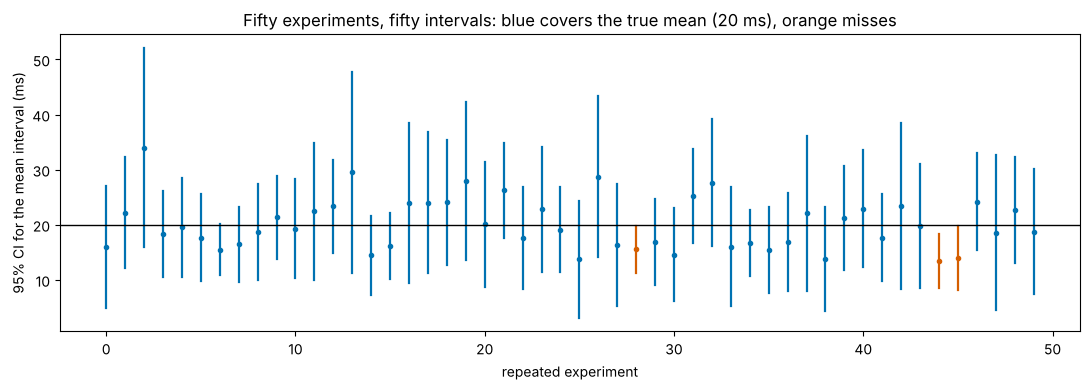

coverage of mean +- 1.96 SE for skewed (exponential) data with n = 15: 0.889 (nominal 0.95)


In [5]:
def wald(k, n, z=1.96):
    p = k / n; h = z * np.sqrt(p * (1 - p) / n)
    return p - h, p + h
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

print(f"{'true p':>7}{'n':>5}{'Wald coverage':>15}{'Wilson coverage':>17}")
for p_true in [0.5, 0.8, 0.95]:
    for n in [20, 100]:
        k = RNG.binomial(n, p_true, 20000)
        for name, f in [('wald', wald), ('wilson', wilson)]:
            lo, hi = f(k, n)
            cov = np.mean((lo <= p_true) & (p_true <= hi))
            if name == 'wald':
                cw = cov
        print(f"{p_true:>7}{n:>5}{cw:>15.3f}{cov:>17.3f}")

# Picture: 50 repeated experiments, each with its own Wald interval for a mean.
fig, ax = plt.subplots(figsize=(11, 4))
mu_true, n_obs = 20.0, 15
for i in range(50):
    x = RNG.exponential(mu_true, n_obs)                                     # skewed data, true mean 20
    se = x.std(ddof=1) / np.sqrt(n_obs)
    lo, hi = x.mean() - 1.96 * se, x.mean() + 1.96 * se
    hit = lo <= mu_true <= hi
    ax.plot([i, i], [lo, hi], color=PALETTE[0] if hit else PALETTE[1], lw=1.6)
    ax.plot(i, x.mean(), 'o', color=PALETTE[0] if hit else PALETTE[1], ms=3)
ax.axhline(mu_true, color='black', lw=1)
ax.set_xlabel('repeated experiment'); ax.set_ylabel('95% CI for the mean interval (ms)')
ax.set_title('Fifty experiments, fifty intervals: blue covers the true mean (20 ms), orange misses')
plt.tight_layout(); plt.show()
cov_mean = []
for _ in range(20000):
    x = RNG.exponential(mu_true, n_obs); se = x.std(ddof=1) / np.sqrt(n_obs)
    cov_mean.append(abs(x.mean() - mu_true) <= 1.96 * se)
print(f"coverage of mean +- 1.96 SE for skewed (exponential) data with n = {n_obs}: {np.mean(cov_mean):.3f} (nominal 0.95)")

For $p = 0.5$ both intervals cover close to 95%. For $p = 0.95$ with 20 trials, the Wald interval covers far less than its stated 95% (when every trial succeeds it has zero width and always misses), while the Wilson interval stays close. For the mean of 15 skewed intervals, $\pm1.96$ SE covers about 89% rather than 95%: the CLT has not yet made the mean Gaussian. **A nominal 95% is a claim; simulation checks it.**

# **Part 3: The Nonparametric Bootstrap**

For many statistics (a median, a Fano factor, a correlation, an AUC, a decoder's accuracy) there is no simple SE formula. The **bootstrap** approximates the sampling distribution by treating the data as a stand-in for the population:

1. From the $n$ observed **independent units** (trials, neurons, animals), draw $n$ units **with replacement**: a bootstrap sample.
2. Recompute the statistic on the bootstrap sample.
3. Repeat $B$ times (typically 1,000–10,000).
4. The SD of the $B$ values estimates the SE; the 2.5th and 97.5th percentiles give a **95% percentile interval**.

**What to resample is the most important decision.** Resample the units that are independent in the design: trials if trials are independent, neurons if the question is about the population of neurons, animals if the question is about mice. Resampling 50 ms bins from a continuous recording, or resampling neurons when the question is about trial-to-trial variability, breaks the dependence structure and gives intervals that are too narrow.

**Limits.** The bootstrap needs a reasonable number of units (it cannot invent variability that the sample does not show), works poorly for statistics determined by extremes (the maximum), and inherits any bias of the estimator. Its coverage, like any interval's, can be checked by simulation.

mean: estimate 17.76 ms;  analytic SE 2.90;  bootstrap SE 2.83;  percentile 95% interval [12.53 23.8 ]
median: estimate 10.69 ms (true median 20 ln 2 = 13.86);  bootstrap SE 2.45;  95% interval [ 7.19 18.29]


coverage of the bootstrap percentile interval for the median (n = 40): 0.950


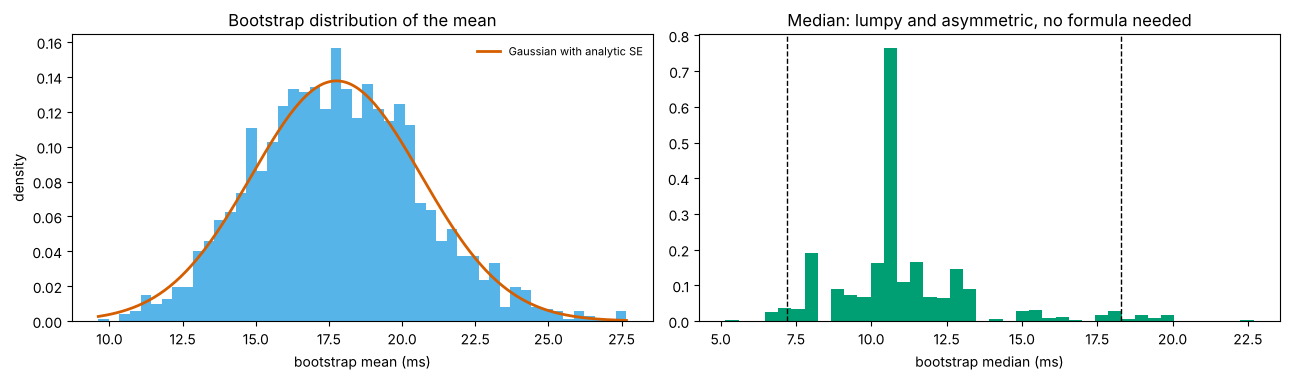

In [6]:
def bootstrap(data, stat, B=2000, rng=RNG, axis_units=0):
    # Nonparametric bootstrap: resample units (rows along axis 0) with replacement. Returns the B bootstrap values.
    data = np.asarray(data)
    n = data.shape[axis_units]
    out = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, n)
        out[b] = stat(data[idx])
    return out

x = RNG.exponential(20.0, 40)                                              # (40,) intervals (ms), one experiment
boot_mean = bootstrap(x, np.mean)
print(f"mean: estimate {x.mean():.2f} ms;  analytic SE {x.std(ddof=1) / np.sqrt(x.size):.2f};  bootstrap SE {boot_mean.std(ddof=1):.2f};  "
      f"percentile 95% interval {np.round(np.percentile(boot_mean, [2.5, 97.5]), 2)}")
boot_med = bootstrap(x, np.median)
print(f"median: estimate {np.median(x):.2f} ms (true median 20 ln 2 = {20 * np.log(2):.2f});  bootstrap SE {boot_med.std(ddof=1):.2f};  "
      f"95% interval {np.round(np.percentile(boot_med, [2.5, 97.5]), 2)}")

# Check: coverage of the bootstrap percentile interval for the median, over 1000 repeated experiments.
cover = 0
for _ in range(1000):
    xs = RNG.exponential(20.0, 40)
    bm = bootstrap(xs, np.median, B=500)
    lo, hi = np.percentile(bm, [2.5, 97.5])
    cover += lo <= 20 * np.log(2) <= hi
print(f"coverage of the bootstrap percentile interval for the median (n = 40): {cover / 1000:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
axes[0].hist(boot_mean, bins=50, density=True, color=PALETTE[5])
xx = np.linspace(boot_mean.min(), boot_mean.max(), 200)
axes[0].plot(xx, stats.norm.pdf(xx, x.mean(), x.std(ddof=1) / np.sqrt(x.size)), color=PALETTE[1], lw=2, label='Gaussian with analytic SE')
axes[0].set_xlabel('bootstrap mean (ms)'); axes[0].set_ylabel('density'); axes[0].set_title('Bootstrap distribution of the mean'); axes[0].legend(fontsize=8, frameon=False)
axes[1].hist(boot_med, bins=40, density=True, color=PALETTE[2])
for q in np.percentile(boot_med, [2.5, 97.5]):
    axes[1].axvline(q, color='black', ls='--', lw=1)
axes[1].set_xlabel('bootstrap median (ms)'); axes[1].set_title('Median: lumpy and asymmetric, no formula needed')
plt.tight_layout(); plt.show()

For the mean, the bootstrap SE agrees with the formula $s/\sqrt n$, and its distribution is close to the Gaussian approximation. For the median there is no simple formula, but the bootstrap gives an interval directly, and its coverage over 1,000 simulated experiments is checked rather than assumed. (The bootstrap distribution of a median is lumpy because it can only take values from the sample.)

#### Interactive version: bootstrap distributions and sample size
The slider changes the number of intervals in the experiment; the frame shows the bootstrap distribution of the median from one experiment of that size.

In [7]:
n_list = [10, 20, 40, 80, 160, 320, 640]
bins_b = np.linspace(0, 45, 91)
def boot_frame(n):
    rr = np.random.default_rng(n)
    xs = rr.exponential(20.0, n)
    bm = bootstrap(xs, np.median, B=2000, rng=rr)
    return np.histogram(bm, bins=bins_b, density=True)[0], np.percentile(bm, [2.5, 97.5]), np.median(xs)
h0, ci0, m0 = boot_frame(n_list[0])
cb = 0.5 * (bins_b[1:] + bins_b[:-1])
fig_b = go.Figure([go.Bar(x=cb, y=np.round(h0, 4), marker_color=PALETTE[2], name='bootstrap medians'),
                   go.Scatter(x=[20 * np.log(2)] * 2, y=[0, 0.6], mode='lines', line=dict(color='black', dash='dot'), name='true median 13.9 ms')])
fr = []
for i, n in enumerate(n_list):
    h, ci, m = boot_frame(n)
    fr.append(go.Frame(name=str(i), traces=[0], data=[go.Bar(y=np.round(h, 4))],
                       layout=go.Layout(title=f'n = {n}: sample median {m:.1f} ms, 95% bootstrap interval [{ci[0]:.1f}, {ci[1]:.1f}] ms')))
fig_b.frames = fr
buttons, sliders = play_pause_and_slider(n_list, prefix='n = ', duration=700)
fig_b.update_layout(title=fr[0].layout.title.text, xaxis=dict(title='bootstrap median (ms)'), yaxis=dict(title='density', range=[0, 0.6]),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_b.show(config=PLOTLY_CONFIG)

# **Part 4: Covariance, Correlation, Confounding and Nonlinearity**

The **Pearson correlation** of paired observations $(x_i, y_i)$ is the covariance divided by both standard deviations (Lesson 17):

$$r = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sqrt{\sum_i (x_i - \bar x)^2}\sqrt{\sum_i (y_i - \bar y)^2}} \in [-1, 1],$$

equivalently the mean product of z-scores. It is unitless and measures **linear** association: $r^2$ is the fraction of the variance of $y$ explained by the best straight line in $x$ (Lesson 5). Three ways it misleads:
- **Nonlinearity:** a strong but non-monotonic relationship (a tuning curve peaking in the middle) can have $r \approx 0$.
- **Outliers:** one extreme point can create or destroy a correlation. The **Spearman** correlation (Pearson on the ranks) is more robust and captures any monotonic relationship.
- **Confounding:** a third variable $Z$ that drives both $X$ and $Y$ creates a correlation between them even if they do not influence each other (Lesson 16's common-cause dependence). Comparing within levels of $Z$, or correlating the **residuals** after regressing out $Z$ (the **partial correlation**), removes the part explained by $Z$; it cannot remove confounders that were not measured.

Correlation is not causation, and a correlation estimated from few pairs is uncertain: bootstrap the **pairs** (keeping each $x_i$ with its $y_i$).

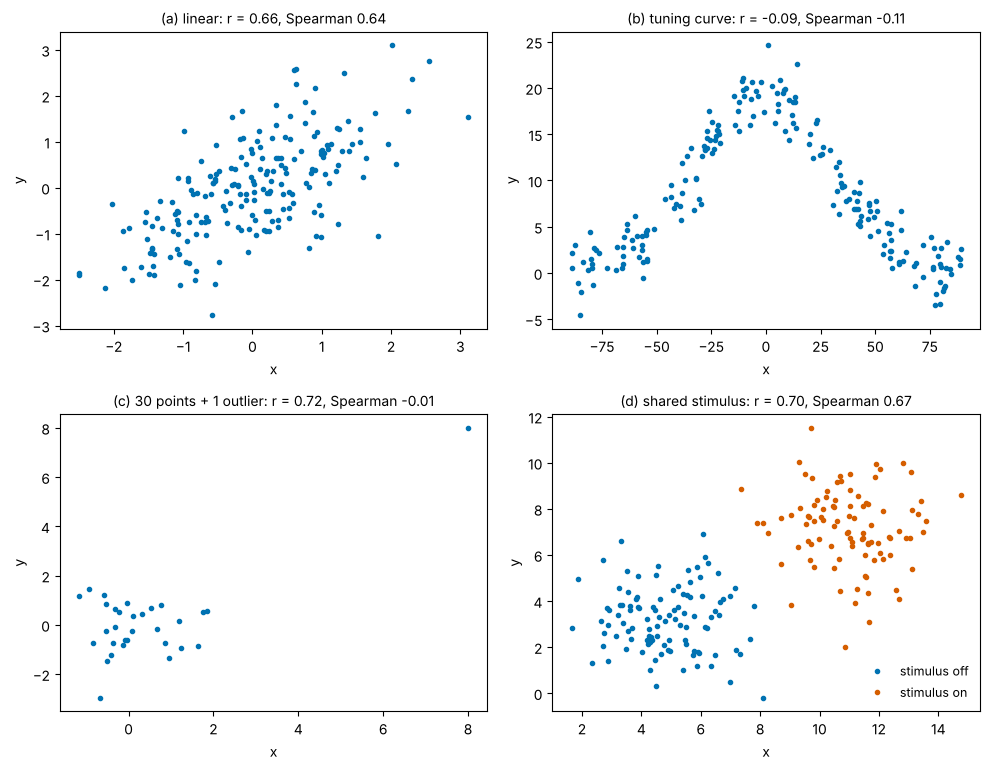

(c) without the outlier: r = -0.02
(d) pooled r = 0.70;  within each stimulus condition r = [-0.06 -0.09];  partial correlation (residuals) = -0.07
(a) bootstrap 95% interval for r (resampling pairs): [0.576 0.732]


In [8]:
def pearson(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    zx, zy = (x - x.mean()) / x.std(), (y - y.mean()) / y.std()
    return np.mean(zx * zy)

n_p = 200
fig, axes = plt.subplots(2, 2, figsize=(10, 7.8))
axes = axes.ravel()
# (a) linear
xa = RNG.normal(0, 1, n_p); ya = 0.6 * xa + RNG.normal(0, 0.8, n_p)
# (b) nonlinear (tuning curve)
xb = RNG.uniform(-90, 90, n_p); yb = 20 * np.exp(-0.5 * (xb / 30)**2) + RNG.normal(0, 2, n_p)
# (c) one outlier
xc = RNG.normal(0, 1, 30); yc = RNG.normal(0, 1, 30); xc = np.r_[xc, 8.0]; yc = np.r_[yc, 8.0]
# (d) confounded: a shared stimulus drives both neurons, which do not interact
stim = RNG.integers(0, 2, n_p)                                              # stimulus on/off
xd = 5 + 6 * stim + RNG.normal(0, 1.5, n_p); yd = 3 + 4 * stim + RNG.normal(0, 1.5, n_p)
panels = [(xa, ya, '(a) linear'), (xb, yb, '(b) tuning curve'), (xc, yc, '(c) 30 points + 1 outlier'), (xd, yd, '(d) shared stimulus')]
for ax, (x_, y_, t) in zip(axes, panels):
    if t.startswith('(d)'):
        for s, c in [(0, PALETTE[0]), (1, PALETTE[1])]:
            ax.plot(x_[stim == s], y_[stim == s], 'o', ms=3, color=c, label=f'stimulus {"on" if s else "off"}')
        ax.legend(fontsize=9, frameon=False, loc='lower right')
    else:
        ax.plot(x_, y_, 'o', ms=3, color=PALETTE[0])
    ax.set_title(f'{t}: r = {pearson(x_, y_):.2f}, Spearman {stats.spearmanr(x_, y_)[0]:.2f}', fontsize=10)
    ax.set_xlabel('x'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()
print(f"(c) without the outlier: r = {pearson(xc[:-1], yc[:-1]):.2f}")
within = [pearson(xd[stim == s], yd[stim == s]) for s in (0, 1)]
res_x = xd - np.where(stim == 1, xd[stim == 1].mean(), xd[stim == 0].mean())    # residuals after removing the stimulus effect
res_y = yd - np.where(stim == 1, yd[stim == 1].mean(), yd[stim == 0].mean())
print(f"(d) pooled r = {pearson(xd, yd):.2f};  within each stimulus condition r = {np.round(within, 2)};  partial correlation (residuals) = {pearson(res_x, res_y):.2f}")
boot_r = bootstrap(np.column_stack([xa, ya]), lambda d: pearson(d[:, 0], d[:, 1]))
print(f"(a) bootstrap 95% interval for r (resampling pairs): {np.round(np.percentile(boot_r, [2.5, 97.5]), 3)}")

- (a) A linear relationship: Pearson and Spearman agree, and the bootstrap gives the uncertainty in $r$.
- (b) The response depends strongly on orientation, but symmetrically: Pearson $r \approx 0$. "No correlation" does not mean "no relationship".
- (c) Thirty unrelated points plus one extreme point give a large Pearson $r$; Spearman is much less affected. Always plot the data.
- (d) The two "neurons" never interact, yet pooled over trials they correlate strongly, because both respond to the stimulus. Within each stimulus condition, or after removing the stimulus effect, the correlation vanishes. In neuroscience this is the distinction between **signal correlation** (shared tuning) and **noise correlation** (shared trial-to-trial variability at fixed stimulus).

# **Part 5: ROC Curves and AUC**

A detector or decoder outputs a **score** on each trial (a spike count, a log-odds). Lesson 16 chose one threshold; the **receiver operating characteristic** (ROC) curve shows all of them at once: for every threshold $t$, the point (false-alarm rate, hit rate) $= \big(P(\text{score} \ge t \mid \text{absent}),\ P(\text{score} \ge t \mid \text{present})\big)$, from "everything yes" (1, 1) to "everything no" (0, 0).

The **area under the curve** (AUC) summarises discrimination across thresholds:

$$\mathrm{AUC} = P(\text{score of a random present trial} > \text{score of a random absent trial}) + \tfrac12 P(\text{tie}),$$

the Mann–Whitney probability. AUC = 0.5 is chance (the diagonal); AUC = 1 is perfect separation.

- AUC depends only on the **ranking** of scores: any increasing transformation of the score (counts → log counts, log-odds → probabilities) leaves it unchanged.
- It does not depend on the **base rate**, since hit and false-alarm rates condition on the truth (Lesson 16).
- Therefore it says nothing about **calibration** (Lesson 19): a decoder with wildly overconfident probabilities can have AUC 0.99. Discrimination and calibration must be checked separately.
- AUC is an estimate with sampling variability: bootstrap the **trials** (keeping each score with its label) for an interval, and resample the same trials for both decoders when comparing two (a **paired** bootstrap).

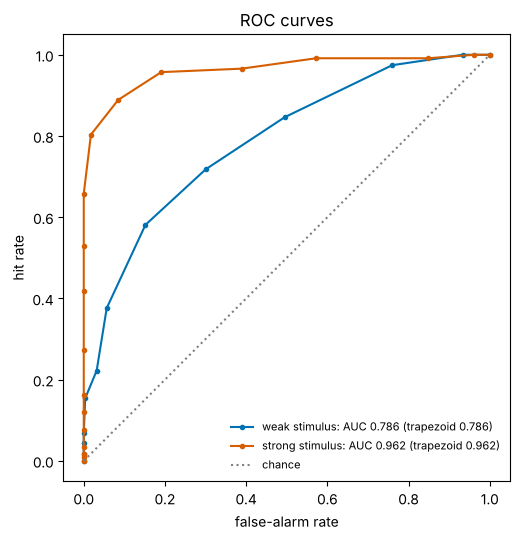

AUC of log(1 + count): 0.962 (unchanged by an increasing transform)
base rate 0.29 -> 0.57: AUC 0.962 -> 0.956 (changes only by sampling noise);  accuracy at 'count >= 6': 0.907 -> 0.879


In [9]:
def roc_curve(score, label):
    # ROC points for thresholds 'score >= t' at every distinct score (plus +inf). label: Boolean truth. Returns (fa, hit), each sorted.
    score, label = np.asarray(score, float), np.asarray(label, bool)
    ts = np.r_[np.inf, np.sort(np.unique(score))[::-1]]
    hit = np.array([np.mean(score[label] >= t) for t in ts])
    fa = np.array([np.mean(score[~label] >= t) for t in ts])
    return fa, hit

def auc_mw(score, label):
    # AUC as the Mann-Whitney probability, ties counted as one half.
    s1, s0 = np.asarray(score)[label], np.asarray(score)[~label]
    return np.mean(s1[:, None] > s0[None, :]) + 0.5 * np.mean(s1[:, None] == s0[None, :])

# Two simulated detectors: spike counts (Poisson) for a weak and a stronger stimulus.
present = RNG.random(400) < 0.3
score_weak = RNG.poisson(np.where(present, 5.0, 3.0)); score_strong = RNG.poisson(np.where(present, 9.0, 3.0))
fig, ax = plt.subplots(figsize=(6, 5.5))
for s, c, lab in [(score_weak, PALETTE[0], 'weak stimulus'), (score_strong, PALETTE[1], 'strong stimulus')]:
    fa, hit = roc_curve(s, present)
    ax.plot(fa, hit, 'o-', color=c, ms=3, lw=1.5, label=f'{lab}: AUC {auc_mw(s, present):.3f} (trapezoid {np.trapezoid(hit, fa):.3f})')
ax.plot([0, 1], [0, 1], ':', color='grey', label='chance')
ax.set_xlabel('false-alarm rate'); ax.set_ylabel('hit rate'); ax.set_aspect('equal'); ax.set_title('ROC curves'); ax.legend(fontsize=8, frameon=False, loc='lower right')
plt.tight_layout(); plt.show()
print(f"AUC of log(1 + count): {auc_mw(np.log1p(score_strong), present):.3f} (unchanged by an increasing transform)")
keep_rare = present | (RNG.random(400) < 0.3)                              # drop most absent trials: base rate changes from 0.3 to about 0.6
print(f"base rate {present.mean():.2f} -> {present[keep_rare].mean():.2f}: AUC {auc_mw(score_strong, present):.3f} -> {auc_mw(score_strong[keep_rare], present[keep_rare]):.3f} "
      f"(changes only by sampling noise);  accuracy at 'count >= 6': {np.mean((score_strong >= 6) == present):.3f} -> {np.mean((score_strong[keep_rare] >= 6) == present[keep_rare]):.3f}")

The area computed by the trapezoid rule under the empirical ROC curve equals the Mann–Whitney probability exactly (with ties counted as one half). Transforming the counts by $\log(1 + x)$ does not change the AUC. Changing the base rate by discarding absent trials changes the AUC only by sampling noise, while the accuracy at a fixed threshold changes systematically.

# **Part 6: Mean–Variance and Dispersion Checks with Error Bars**

Lessons 17–18 compared Fano factors with the Poisson value 1 using simulations of Poisson neurons. The bootstrap adds the other side: an interval for the **observed** Fano factor of each neuron (resampling trials), and an interval for a **population summary** such as the median Fano factor.

Two questions need two different resampling units:
- "How uncertain is **this neuron's** Fano factor?" — resample **trials**.
- "How uncertain is the median Fano factor of **neurons in this area**, as a population?" — resample **neurons** (and, ideally, trials within neurons; with one session, resampling trials for all neurons together keeps their shared fluctuations intact).

The mini-lab uses both.

# **Part 7: Mini-Lab — Error Bars on Earlier Conclusions**

**Data.** The Lesson 16–19 session (Steinmetz et al., 2019; mouse Lederberg): spike counts 50–250 ms after onset, `counts` (340, 698); `brain_area` (698,); contrasts (340,). We revisit three earlier conclusions and ask how firm they are.
1. Lesson 19's naive-Bayes VISp decoder is better at **discriminating** right gratings than Lesson 16's summed count. Is it, given the test sample size?
2. Two VISp neurons are strongly correlated. How much of that is the stimulus?
3. Lesson 17's median Fano factor of 1.5. How uncertain is it?

In [10]:
import os, urllib.request
STEIN_FILE = 'steinmetz_s11_lederberg.npz'
for cand in [STEIN_FILE, os.path.join('..', '..', 'data', STEIN_FILE)]:
    if os.path.exists(cand):
        stein_path = cand; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/8f9e0431a21d8ac0aa016e3502735f3b8627863a/data/' + STEIN_FILE, STEIN_FILE)
    stein_path = STEIN_FILE
dat = np.load(stein_path)
spk = dat['counts'].astype(float); area = dat['brain_area']
cl, cr = dat['contrast_left'], dat['contrast_right']
X = spk[:, area == 'VISp']; R = cr > 0; n_tr = len(R)                    # (340, 66), (340,)
split = np.random.default_rng(42).permutation(n_tr)                         # the same split as Lesson 19
tr = np.zeros(n_tr, bool); tr[split[:n_tr // 2]] = True; te = ~tr
lam1 = (X[tr & R].sum(axis=0) + 0.1) / ((tr & R).sum() + 0.1); lam0 = (X[tr & ~R].sum(axis=0) + 0.1) / ((tr & ~R).sum() + 0.1)
score_nb = (X * np.log(lam1 / lam0) - (lam1 - lam0)).sum(axis=1)          # (340,) naive-Bayes log-likelihood ratio
score_sum = X.sum(axis=1)                                                  # (340,) summed VISp count (Lesson 16)
idx_te = np.where(te)[0]
auc_sum, auc_nb = auc_mw(score_sum[te], R[te]), auc_mw(score_nb[te], R[te])
rng_b = np.random.default_rng(1)
b_sum, b_nb, b_diff = [], [], []
for b in range(2000):
    i = rng_b.choice(idx_te, idx_te.size)                                   # resample TEST TRIALS, the same trials for both scores (paired)
    if R[i].all() or (~R[i]).all():
        continue
    a1, a2 = auc_mw(score_sum[i], R[i]), auc_mw(score_nb[i], R[i])
    b_sum.append(a1); b_nb.append(a2); b_diff.append(a2 - a1)
print(f"test trials: {te.sum()};  AUC summed count {auc_sum:.3f} [95% bootstrap {np.percentile(b_sum, 2.5):.3f}, {np.percentile(b_sum, 97.5):.3f}]")
print(f"             AUC naive Bayes  {auc_nb:.3f} [{np.percentile(b_nb, 2.5):.3f}, {np.percentile(b_nb, 97.5):.3f}]")
print(f"paired difference (naive Bayes - summed) {auc_nb - auc_sum:.3f} [{np.percentile(b_diff, 2.5):.3f}, {np.percentile(b_diff, 97.5):.3f}]")
print(f"recall Lesson 19: the naive-Bayes posteriors were badly miscalibrated, yet its AUC is {auc_nb:.3f}")

test trials: 170;  AUC summed count 0.963 [95% bootstrap 0.937, 0.984]
             AUC naive Bayes  0.999 [0.996, 1.000]
paired difference (naive Bayes - summed) 0.035 [0.016, 0.061]
recall Lesson 19: the naive-Bayes posteriors were badly miscalibrated, yet its AUC is 0.999


all 340 trials (pooled)   : n = 340, r = 0.791 [95% bootstrap 0.747, 0.831]


no right grating          : n = 167, r = 0.162 [95% bootstrap 0.006, 0.369]


right contrast 1          : n =  73, r = 0.374 [95% bootstrap 0.167, 0.570]


partial correlation after removing the right-contrast means: r = 0.317 [0.193, 0.434]



median Fano factor (blank trials, 162 neurons): 1.50;  95% interval resampling trials [1.41 1.56], resampling neurons [1.41 1.61]


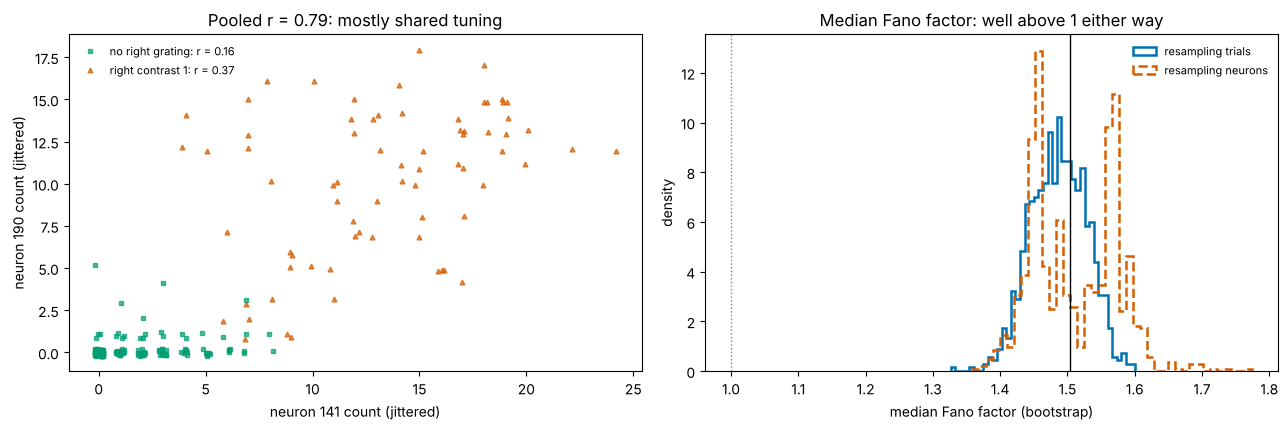

In [11]:
vis_idx = np.where(area == 'VISp')[0]
pair = vis_idx[np.argsort(-spk[:, vis_idx].mean(axis=0))[:2]]                # the two highest-rate VISp neurons
xa_, xb_ = spk[:, pair[0]], spk[:, pair[1]]                                # (340,) each
def r_ci(x, y, B=2000, rng=np.random.default_rng(2)):
    bb = bootstrap(np.column_stack([x, y]), lambda d: pearson(d[:, 0], d[:, 1]), B=B, rng=rng)
    return pearson(x, y), np.percentile(bb, [2.5, 97.5])
rows = [('all 340 trials (pooled)', np.ones(n_tr, bool)), ('no right grating', cr == 0), ('right contrast 1', cr == 1)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for (lab, m), c, mk in zip(rows, [PALETTE[0], PALETTE[2], PALETTE[1]], MARKERS):
    r_, ci_ = r_ci(xa_[m], xb_[m])
    print(f"{lab:<26}: n = {m.sum():>3}, r = {r_:.3f} [95% bootstrap {ci_[0]:.3f}, {ci_[1]:.3f}]")
    if lab.startswith('all'):
        continue
    axes[0].plot(xa_[m] + RNG.uniform(-0.2, 0.2, m.sum()), xb_[m] + RNG.uniform(-0.2, 0.2, m.sum()), mk, ms=3.5, color=c, alpha=0.7, label=f'{lab}: r = {r_:.2f}')
axes[0].set_xlabel(f'neuron {pair[0]} count (jittered)'); axes[0].set_ylabel(f'neuron {pair[1]} count (jittered)')
axes[0].set_title(f'Pooled r = {pearson(xa_, xb_):.2f}: mostly shared tuning'); axes[0].legend(fontsize=8, frameon=False)
res_a = xa_ - np.array([xa_[cr == c].mean() for c in cr])                   # residuals after removing each right-contrast condition's mean
res_b = xb_ - np.array([xb_[cr == c].mean() for c in cr])
r_part, ci_part = r_ci(res_a, res_b)
print(f"partial correlation after removing the right-contrast means: r = {r_part:.3f} [{ci_part[0]:.3f}, {ci_part[1]:.3f}]")

# Dispersion: median Fano factor of neurons on blank trials, with two kinds of bootstrap.
blank = (cl == 0) & (cr == 0)
Xb = spk[blank]                                                             # (108, 698)
keep = Xb.mean(axis=0) >= 1.0
def med_ff(M):
    m = M.mean(axis=0); return np.median(M.var(axis=0, ddof=1)[m > 0] / m[m > 0])
ff_obs = med_ff(Xb[:, keep])
boot_trials = bootstrap(Xb[:, keep], med_ff, B=1000, rng=np.random.default_rng(3))          # resample trials (rows)
boot_neurons = bootstrap(Xb[:, keep].T, lambda M: med_ff(M.T), B=1000, rng=np.random.default_rng(4))   # resample neurons
print(f"\nmedian Fano factor (blank trials, {keep.sum()} neurons): {ff_obs:.2f};  95% interval resampling trials {np.round(np.percentile(boot_trials, [2.5, 97.5]), 2)}, "
      f"resampling neurons {np.round(np.percentile(boot_neurons, [2.5, 97.5]), 2)}")
axes[1].hist(boot_trials, bins=40, density=True, histtype='step', lw=1.8, color=PALETTE[0], label='resampling trials')
axes[1].hist(boot_neurons, bins=40, density=True, histtype='step', lw=1.8, ls='--', color=PALETTE[1], label='resampling neurons')
axes[1].axvline(1, color='grey', ls=':', lw=1); axes[1].axvline(ff_obs, color='black', lw=1)
axes[1].set_xlabel('median Fano factor (bootstrap)'); axes[1].set_ylabel('density'); axes[1].set_title('Median Fano factor: well above 1 either way')
axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

**Reading the mini-lab.**
- **Decoders.** On 170 test trials the summed count has AUC about 0.96 and the naive-Bayes decoder about 0.999. The paired bootstrap interval for the difference excludes 0: the naive-Bayes decoder discriminates better, even though (Lesson 19) its probabilities are badly miscalibrated. AUC and calibration answer different questions. Resampling the **same** test trials for both decoders matters: the two scores are evaluated on the same trials, so their errors are correlated, and an unpaired comparison would overstate the uncertainty of the difference.
- **Correlation.** The two VISp neurons correlate strongly when all trials are pooled ($r \approx 0.8$), because both respond to right gratings (**signal correlation**). Within a fixed stimulus condition the correlation is much smaller (about 0.16 without a right grating and 0.37 at full contrast), and the partial correlation after removing each condition's mean is in between. Most of the pooled correlation is the stimulus; what remains is **noise correlation**, the shared variability that broke Lesson 19's naive-Bayes posteriors. The within-condition intervals are wide: 73 and 167 trials pin down a correlation only to about $\pm0.15$–$0.2$.
- **Dispersion.** The median Fano factor of 1.5 on blank trials is well above 1 whether we resample trials (uncertainty from trial-to-trial sampling) or neurons (uncertainty about the population of neurons); the two intervals answer different questions and both exclude 1 comfortably.

**Limitations.** One session and one split; bootstrap intervals assume trials are independent, but trials close in time share slow drifts, so these intervals are probably somewhat too narrow; resampling neurons treats the recorded neurons as a random sample of the area, which a single probe track is not.

# **Part 8: Applications in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Bias, SE, MSE | estimating rates, tuning parameters, information from limited trials (bias corrections) | bias–variance trade-off; regularisation |
| Confidence intervals and coverage | error bars on every reported effect; power and sample-size planning | error bars on test metrics; comparing models fairly |
| Bootstrap | intervals for Fano factors, tuning widths, decoding accuracy, latencies; resampling trials, neurons or animals (hierarchical bootstrap) | bootstrap aggregation (bagging); uncertainty of evaluation metrics |
| Correlation, confounding | signal vs noise correlations; behavioural confounds of neural activity (movement, arousal) | spurious correlations; leakage; causal vs predictive features |
| Nonlinearity | tuning curves invisible to linear correlation; mutual information as an alternative | nonlinear dependence measures; feature engineering |
| ROC and AUC | choice probability and detect probability (ROC analysis of single neurons); spike-sorting quality | classifier evaluation independent of threshold and base rate |
| Calibration vs discrimination | confidence reports; decoder probabilities | reliability diagrams; calibrated classifiers |
| Dispersion checks | Fano factors, mean–variance relations, model checking of spike-count models | posterior predictive and goodness-of-fit checks |

# **Part 9: Summary, Exit Ticket and Lesson 21 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Sampling distribution | distribution of $\hat\theta$ over repeated experiments | estimates are random variables |
| Bias, SE, MSE | $E[\hat\theta] - \theta$; $\operatorname{SD}(\hat\theta)$; $\text{bias}^2 + \text{SE}^2$ | SD describes data, SE describes an estimate; simulate to check |
| 95% CI | $\hat\theta \pm 1.96\,\mathrm{SE}$; Wilson for proportions | a property of the procedure (coverage), not of one interval |
| Bootstrap | resample independent units with replacement; percentiles | choose the unit to match the question; check coverage |
| Pearson / Spearman | mean product of z-scores; correlation of ranks | linear (or monotonic) only; plot the data; outliers |
| Confounding | compare within levels of $Z$; partial correlation | signal vs noise correlation; unmeasured confounders remain |
| ROC / AUC | hit vs false-alarm rate over thresholds; $P(s_1 > s_0)$ | rank-based, base-rate free, blind to calibration; paired bootstrap for comparisons |
| Dispersion | Fano factor with bootstrap and Poisson-null intervals | two uncertainties: trials and neurons |

**Exit ticket.** A paper reports "the decoder achieved AUC = 0.92 (n = 30 trials) and its correlation with behaviour was r = 0.45". Name three things you would ask before believing the claims.

*(Suggested answer: confidence intervals (with 30 trials, AUC 0.92 and r = 0.45 are both uncertain; r = 0.45 from 30 pairs has a 95% interval roughly 0.1–0.7), and what was resampled; whether the AUC was computed on held-out trials and whether the decoder's probabilities are calibrated if they are used as probabilities; whether the correlation with behaviour is confounded (both driven by the stimulus or by arousal) or driven by an outlier or a nonlinearity, and a plot of the data.)*

**Lesson 21 — ODEs and the passive membrane.** The probability block ends here. Next, the course turns to how quantities change in time: differential equations, starting with the membrane equation $\tau\,dV/dt = -(V - E_L) + R I(t)$, its equilibrium, time constant and exponential approach, and the Euler method for simulating it.

**Further reading.** B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap* (1993); L. Wasserman, *All of Statistics* (2004), Chapters 6–8; T. Fawcett, "An introduction to ROC analysis", *Pattern Recognition Letters* 27 (2006); M. R. Cohen and A. Kohn, "Measuring and interpreting neuronal correlations", *Nature Neuroscience* 14 (2011); V. Saravanan, G. J. Berman and S. J. Sober, "Application of the hierarchical bootstrap to multi-level data in neuroscience", *Neurons, Behavior, Data analysis, and Theory* 3 (2020).